In [358]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)

# import stata_setup
# stata_setup.config('C:/Users/Farid Srouji/OneDrive/Stata15/', 'mp')
# import sys
# sys.path.append("C:/Users/Farid Srouji/OneDrive/Stata15/utilities")
# from pystata import config
# config.init()

In [359]:
import ipystata  

In [360]:
%%stata  
display "Hello, I am printed in Stata." 
describe


Hello, I am printed in Stata.

Contains data
  obs:             0                          
 vars:             0                          
 size:             0                          
Sorted by: 


In [361]:
%%stata 
scatter mpg price


variable mpg not found
r(111);

end of do-file
r(111);


In [362]:
%%stata
sysuse sp500, clear
graph twoway line high low date


(S&P 500)


In [363]:
# Reading the saved data pickle file
df_vix = pd.read_pickle('/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/data/pkl/pickled_one_year_filtered_lead_para_sp500_clean.pkl')

In [364]:
%%stata
sysuse sp500, clear

#graph twoway line close date


(S&P 500)
Unknown #command


In [365]:
df_vix

,close,adj close,articles
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate..."
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....
...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...


In [366]:
#df_vix.columns = ['date', 'close', 'adj close', 'articles']
#df_vix[['date', 'close']] = df_vix['close'].split(' ', 1, expand=True)
#df_vix = pd.DataFrame(df_vix.close.first.split(' ',1).tolist(),
                                 #columns = ['date','close'])
#print(df_vix.close. to_string().split(' ',1))
#df_new = pd.DataFrame(df_vix.close.to_string().split(' ',1), columns = ['date','close'])
#print(type(df_vix.close.to_list().))
df_vix
#df_vix = pd.DataFrame(df_vix.close.to_string().split(' ',1), columns = ['date','close'])

,close,adj close,articles
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate..."
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....
...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...


In [367]:
#df_vix.reset_index(level=0, inplace=True)
df_vix['VIX'] = df_vix['adj close'].apply(np.int)

#df_vix['date'] = df_vix.index

In [368]:
df_vix#from pandas import DataFrame

#df1 = DataFrame(df_vix[df_vix.columns[0]].to_string().split(" ",569), columns=['date'])
# ts=pd.Series(df_vix[df_vix.columns[0]], index=pd.date_range("25/09/2019", periods=569))
# ts.plot()

,close,adj close,articles,VIX
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...,17
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...,17
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate...",17
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...,17
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....,17
...,...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...,16
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...,17
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...,17
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...,17


In [369]:
#df_vix = df_vix.reset_index()

In [370]:
#df_vix['index']

In [371]:
#df_vix = df_vix.reset_index()
# df_vix['adj close'] = df_vix['adj close'].apply(np.float64) + 0.5
#df_vix['VIX'] = df_vix['adj close']
df_vix.columns.values[1] = "VIX"
#decimals = 2
#df_vix['VIX'] = df_vix['adj close'].apple(np.round)
#df_vix['text'] = df_vix['articles'].str()

In [372]:
df_vix

,close,VIX,articles,VIX
2011-01-04,17.379999,17.379999,. A Push to Privatize Pennsylvania Liquor Stor...,17
2011-01-05,17.020000,17.020000,. A Turnaround for Anadarko. Don’t Call It a C...,17
2011-01-06,17.400000,17.400000,". Health Spending Rose in ’09, but at Low Rate...",17
2011-01-07,17.139999,17.139999,. MBIA Fights Banks for Its Life. Obama Plan A...,17
2011-01-08,17.273333,17.273333,. Flex Time Flourishes in Accounting Industry....,17
...,...,...,...,...
2021-05-28,16.760000,16.760000,. Coast Guard Search Fails to Locate 10 Cuban ...,16
2021-05-29,17.045000,17.045000,. Anniversary Event for Tulsa Race Massacre Un...,17
2021-05-30,17.330000,17.330000,. A Nashville hat store sold ‘Not Vaccinated’ ...,17
2021-05-31,17.615000,17.615000,The Internet’s Favorite Catalog of Weird Place...,17


In [373]:
# selecting the VIX and articles
df_vix = df_vix[['VIX', 'articles']]

In [374]:
#df_vix['articles'] = df_vix['articles'].map(lambda x: x.lstrip('.-'))

In [375]:
df_vix

,VIX,articles
2011-01-04,17,. A Push to Privatize Pennsylvania Liquor Stor...
2011-01-05,17,. A Turnaround for Anadarko. Don’t Call It a C...
2011-01-06,17,". Health Spending Rose in ’09, but at Low Rate..."
2011-01-07,17,. MBIA Fights Banks for Its Life. Obama Plan A...
2011-01-08,17,. Flex Time Flourishes in Accounting Industry....
...,...,...
2021-05-28,16,. Coast Guard Search Fails to Locate 10 Cuban ...
2021-05-29,17,. Anniversary Event for Tulsa Race Massacre Un...
2021-05-30,17,. A Nashville hat store sold ‘Not Vaccinated’ ...
2021-05-31,17,The Internet’s Favorite Catalog of Weird Place...


In [376]:
df = df_vix[['VIX']].copy()
df


,VIX
2011-01-04,17
2011-01-05,17
2011-01-06,17
2011-01-07,17
2011-01-08,17
...,...
2021-05-28,16
2021-05-29,17
2021-05-30,17
2021-05-31,17


In [377]:
df_vix = df_vix.reindex(np.random.permutation(df_vix.index))  
df_vix = df_vix[['VIX', 'articles']]

In [378]:
# Adding new columns to the data frame
df['compound'] = ''
df['neg'] = ''
df['neu'] = ''
df['pos'] = ''

In [379]:
df

,VIX,compound,neg,neu,pos
2011-01-04,17,,,,
2011-01-05,17,,,,
2011-01-06,17,,,,
2011-01-07,17,,,,
2011-01-08,17,,,,
...,...,...,...,...,...
2021-05-28,16,,,,
2021-05-29,17,,,,
2021-05-30,17,,,,
2021-05-31,17,,,,


In [380]:
#import nltk
#nltk.download('vader_lexicon')

--
The date is:2018-04-16 00:00:00
============sentiment status============
compound=-0.9917
neg=0.175
neu=0.723
pos=0.102
ForGraph=36.8231046931408
----------start sentenct-------
Exception for word=.
Exception for word=a
Exception for word=I
Exception for word=4
Exception for word=a
Exception for word=a
Exception for word=7
Exception for word=a
Exception for word=3
Exception for word=2
Exception for word=a
Exception for word=a
----------end sentenct-------
The date is:2014-05-14 00:00:00
============sentiment status============
compound=-0.9936
neg=0.137
neu=0.777
pos=0.086
ForGraph=38.56502242152466
----------start sentenct-------
Exception for word=.
Exception for word=A
Exception for word=a
Exception for word=a
Exception for word=3
Exception for word=a
Exception for word=a
Exception for word=A
Exception for word=a
Exception for word=a
Exception for word=a
Exception for word=A
Exception for word=A
Exception for word=a
Exception for word=a
Exception for word=a
Exception for word=4
E

<BarContainer object of 3 artists>

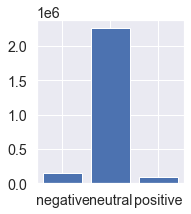

In [381]:
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import unicodedata
sid = SentimentIntensityAnalyzer()
countNeg=0
countNeu=0
countPos=0
#print(df_vix['articles'])
countNegWord=0
countNeuWord=0
countPosWord=0
for date, row in df_vix.T.iteritems():
    print("The date is:"+str(date))
    try:
        sentence = unicodedata.normalize('NFKD', df_vix.loc[date, 'articles'])#.encode('ascii','ignore').decode('ascii')
        #sentence = unicodedata.normalize('NFKD', df_vix.loc[date, 'articles']).encode('ascii','ignore')
        # add my own sentence Options sentiment.
        #print("#1")
        #print (df_vix.loc[date, 'articles'])
        ss = sid.polarity_scores(sentence)
        #print(sentence)
        #print("#2")
        df.at[date, 'compound'] = ss['compound']
        df.at[date, 'neg'] = ss['neg']
        df.at[date, 'neu'] = ss['neu']
        df.at[date, 'pos'] = ss['pos']
        if ((ss['pos'] + ss['neg']) != 0):
            df.at[date, 'ForGraph'] = 100*(ss['pos'] / (ss['pos'] + ss['neg']))
        countNeg+=ss['neg']
        countNeu+=ss['neu']
        countPos+=ss['pos']
        
        print("============sentiment status============")
        print("compound="+str(df.at[date, 'compound']))
        print("neg="+str(df.at[date, 'neg']))
        print("neu="+str(df.at[date, 'neu']))
        print("pos="+str(df.at[date, 'pos']))
        print("ForGraph="+str(df.at[date, 'ForGraph']))
        #print("Sentence="+sentence)
        words = sentence.split()
        print("----------start sentenct-------")

        for word in words:
            try:
                #print("word="+word)
                ww = sid.polarity_scores(word)
                if (ww['neg']==1):
                    countNegWord+=1
                elif (ww['neu']==1):
                    countNeuWord+=1
                elif (ww['pos']==1):
                    countPosWord+=1
                else :
                    print("Error ww="+ww)
            except:
                print("Exception for word="+word)

        print("----------end sentenct-------")

        #print("passed")
    except TypeError:
        #print("sentence is")
        #print(sentence)
        #print(df_vix.loc[date, 'articles'])
        print("ERROR")
        df.at[date, 'compound'] = 0
        df.at[date, 'neg'] = 0
        df.at[date, 'neu'] = 0
        df.at[date, 'pos'] = 0
#df.diff().hist(color="k", alpha=0.5, bins=50);
names = ['negative', 'neutral', 'positive']
values = [countNegWord, countNeuWord, countPosWord]

plt.figure(figsize=(9, 3))

plt.subplot(131)
plt.bar(names, values)


147094
2260678
95238


<BarContainer object of 2 artists>

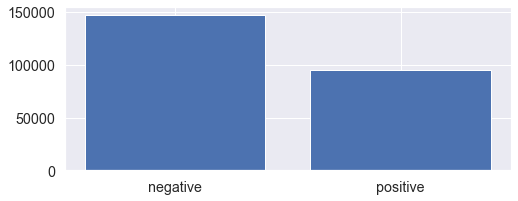

In [382]:
print(countNegWord)
print(countNeuWord)
print(countPosWord)
names = ['negative', 'positive']
values = [countNegWord, countPosWord]
plt.figure(figsize=(8, 3))

plt.bar(names, values)

{'whiskers': [<matplotlib.lines.Line2D at 0x1ebcfcfaaf0>,
 'caps': [<matplotlib.lines.Line2D at 0x1ebd0313460>,
 'boxes': [<matplotlib.lines.Line2D at 0x1ebcfcfa2b0>,
 'medians': [<matplotlib.lines.Line2D at 0x1ebd0313d90>,
 'fliers': [<matplotlib.lines.Line2D at 0x1ebc5d30040>,
 'means': []}

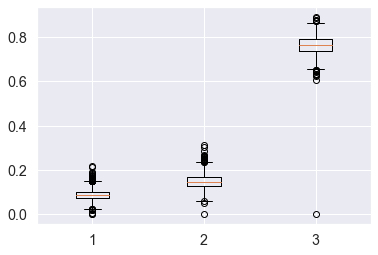

In [383]:
df
df[['pos', 'neg', 'neu']]
# Creating plot
plt.boxplot(df[['pos', 'neg', 'neu']])
 
# # show plot
plt.show()

In [384]:
# df.to_csv(r'/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/data/stata/sentiment.csv', index = False)
# df.to_csv(r'/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/data/stata/sentiment.csv', index = False)


Total Neg=566.2829999999999 | Total Neu=2899.224999999999 | Total Pos=335.51800000000094


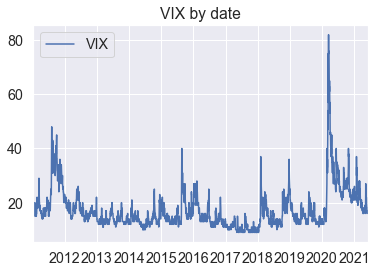

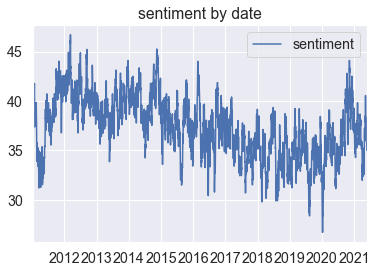

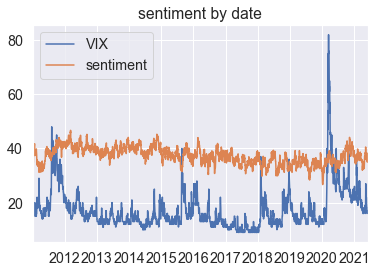

In [385]:
#plt.figure();
#df['sentiment'] = df['ForGraph']#.ewm(span=20).mean()
#print(df.values)
#senDF = df.values
#senDF.all.hist(color="k", alpha=0.5, bins=50);

print("Total Neg="+str(countNeg)+" | Total Neu="+str(countNeu)+" | Total Pos="+str(countPos))

#df = pd.Series(data=df, index=pd.date_range("09/25/2019", periods=569))
df['sentiment'] = df['ForGraph'].ewm(span=20).mean()
# ts=pd.Series(df['sentiment'], index=pd.date_range("25/09/2019", periods=569))
# ts.plot()
df[['VIX']].plot(title='VIX by date')
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/VIX.png")

#df[['ForGraph']].plot(title='sentiment by date')
df[['sentiment']].plot(title='sentiment by date')
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/sentiment.png")
df[['VIX','sentiment']].plot(title='sentiment by date',)
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/sentimentVIX.png")
#sns.boxplot(x='diagnosis', y='area_mean', data=df)
#df.at[date, 'pos'].plot(title='Sentiment by date')
# ts=pd.Series(df['VIX'])#, index=pd.date_range("25/09/2019", periods=569))
# ts.plot()
# df_vix.diff().hist(color="k", alpha=0.5, bins=50);
# ts.plot()
#predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()


In [386]:
df[['VIX', 'compound', 'neg', 'neu', 'pos', 'sentiment']]

,VIX,compound,neg,neu,pos,sentiment
2011-01-04,17,-0.9992,0.18,0.71,0.109,37.716263
2011-01-05,17,-0.9925,0.183,0.731,0.086,34.699612
2011-01-06,17,-0.9956,0.211,0.711,0.078,31.868549
2011-01-07,17,-0.989,0.162,0.722,0.115,34.653690
2011-01-08,17,-0.9963,0.199,0.684,0.117,35.227366
...,...,...,...,...,...,...
2021-05-28,16,-0.9275,0.109,0.8,0.092,38.278432
2021-05-29,17,-0.9897,0.142,0.81,0.048,37.038882
2021-05-30,17,-0.9934,0.166,0.804,0.03,34.969096
2021-05-31,17,-0.5139,0.104,0.795,0.1,36.307240


In [387]:
df_sentiment = df['sentiment'].apply(np.int)

In [388]:
df_sentiment

2011-01-04    37
2011-01-05    34
2011-01-06    31
2011-01-07    34
2011-01-08    35
              ..
2021-05-28    38
2021-05-29    37
2021-05-30    34
2021-05-31    36
2021-06-01    35
Freq: D, Name: sentiment, Length: 3802, dtype: int64

In [389]:
sentence = 'The shooting in Paris killed two'
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import unicodedata
sid = SentimentIntensityAnalyzer()
sid
ss = sid.polarity_scores(sentence)
ss

{'neg': 0.474, 'neu': 0.526, 'pos': 0.0, 'compound': -0.6705}

In [390]:
# df_sentiment['sentiment'] = df
# target_dist = sns.factorplot(x='data',data=df_sentiment, kind="count", size=20, aspect=1.5, palette="PuBuGn_d")
#target_dist.plot()
# plt.show();
# target_dist.savefig('/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/target_dist_vix.png')
# target_dist = sns.factorplot(x="sentiment", data=df, kind="count", size=20, aspect=1.5, palette="PuBuGn_d")
# plt.show();
# target_dist.savefig('/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/financialmodelingprep/images/target_dist_sentiment.png')

In [391]:
# Checking date for empty strings
for date, row in df_vix.T.iteritems():
    if type(df_vix.loc[date, 'articles']).__name__ == 'str':
        print(date)

2017-01-07 00:00:00
2016-08-17 00:00:00
2020-10-11 00:00:00
2021-05-10 00:00:00
2018-12-22 00:00:00
2016-03-08 00:00:00
2018-09-11 00:00:00
2015-07-18 00:00:00
2013-06-30 00:00:00
2011-03-20 00:00:00
2012-05-29 00:00:00
2014-04-12 00:00:00
2018-11-04 00:00:00
2014-05-15 00:00:00
2011-12-02 00:00:00
2012-12-04 00:00:00
2016-09-10 00:00:00
2012-10-10 00:00:00
2013-06-13 00:00:00
2019-04-02 00:00:00
2020-09-08 00:00:00
2013-11-15 00:00:00
2020-02-14 00:00:00
2015-01-10 00:00:00
2017-09-03 00:00:00
2018-03-04 00:00:00
2012-09-18 00:00:00
2014-08-30 00:00:00
2021-03-16 00:00:00
2011-06-24 00:00:00
2012-11-01 00:00:00
2012-06-27 00:00:00
2011-09-17 00:00:00
2014-10-16 00:00:00
2014-04-13 00:00:00
2016-10-28 00:00:00
2015-06-08 00:00:00
2019-11-07 00:00:00
2018-11-18 00:00:00
2020-05-22 00:00:00
2019-12-01 00:00:00
2016-06-07 00:00:00
2019-06-05 00:00:00
2015-10-02 00:00:00
2016-05-09 00:00:00
2020-11-02 00:00:00
2021-03-15 00:00:00
2013-12-25 00:00:00
2017-02-15 00:00:00
2016-09-12 00:00:00


In [392]:
df

,VIX,compound,neg,neu,pos,ForGraph,sentiment
2011-01-04,17,-0.9992,0.18,0.71,0.109,37.716263,37.716263
2011-01-05,17,-0.9925,0.183,0.731,0.086,31.970260,34.699612
2011-01-06,17,-0.9956,0.211,0.711,0.078,26.989619,31.868549
2011-01-07,17,-0.989,0.162,0.722,0.115,41.516245,34.653690
2011-01-08,17,-0.9963,0.199,0.684,0.117,37.025316,35.227366
...,...,...,...,...,...,...,...
2021-05-28,16,-0.9275,0.109,0.8,0.092,45.771144,38.278432
2021-05-29,17,-0.9897,0.142,0.81,0.048,25.263158,37.038882
2021-05-30,17,-0.9934,0.166,0.804,0.03,15.306122,34.969096
2021-05-31,17,-0.5139,0.104,0.795,0.1,49.019608,36.307240


In [393]:
class TextCounts(BaseEstimator, TransformerMixin):
    
    def count_regex(self, pattern, tweet):
        return len(re.findall(pattern, tweet))
    
    def fit(self, X, y=None, **fit_params):
        # fit method is used when specific operations need to be done on the train data, but not on the test data
        return self
    
    def transform(self, X, **transform_params):
        count_words = X.apply(lambda x: self.count_regex(r'\w+', x)) 
        count_mentions = X.apply(lambda x: self.count_regex(r'@\w+', x))
        count_hashtags = X.apply(lambda x: self.count_regex(r'#\w+', x))
        count_capital_words = X.apply(lambda x: self.count_regex(r'\b[A-Z]{2,}\b', x))
        count_excl_quest_marks = X.apply(lambda x: self.count_regex(r'!|\?', x))
        count_urls = X.apply(lambda x: self.count_regex(r'http.?://[^\s]+[\s]?', x))
        # Moreover, it will result in having more words in the tweet
        
        df = pd.DataFrame({'count_words': count_words
                           , 'count_mentions': count_mentions
                           , 'count_hashtags': count_hashtags
                           , 'count_capital_words': count_capital_words
                           , 'count_excl_quest_marks': count_excl_quest_marks
                           , 'count_urls': count_urls
                          })
        
        return df

In [394]:
tc = TextCounts()
df_eda = tc.fit_transform(df_vix.articles)


In [395]:
def show_dist(df, col):
    print('Descriptive stats for {}'.format(col))
    print('-'*(len(col)+22))
    print(df.groupby('VIX')[col].describe())
    bins = np.arange(df[col].min(), df[col].max() + 1)
    g = sns.FacetGrid(df, col='VIX', size=5, hue='VIX', palette="PuBuGn_d")
    g = g.map(sns.distplot, col, kde=False, norm_hist=True, bins=bins)
    plt.show()

In [396]:
fafds

NameError: name 'fafds' is not defined

In [ ]:
df_vixs=df[['VIX']]
target_dist = sns.factorplot(x="VIX", data=df_vixs, kind="count", size=10, aspect=1.5, palette="PuBuGn_d")
plt.show();
target_dist.savefig('/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/VIX_Histogram.png')

In [ ]:
#show_dist(df_vixs, 'VIX')

In [ ]:
df

In [ ]:
# train_start_date = '1'
# train_end_date = '569'
# test_start_date = '1'
# test_end_date = '569'

train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'

#test_start_date = '2012-01-01'
#test_end_date = '2018-12-31'
train = df.loc[train_start_date : train_end_date]
print(test_start_date)
test = df.loc[test_start_date:test_end_date]
print(test_end_date)


In [ ]:
sentiment_score_list = []
for date, row in train.T.iteritems():
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)

In [ ]:
sentiment_score_list = []
for date, row in test.T.iteritems():
    print(date)
    #sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

In [ ]:
y_train = pd.DataFrame(train['VIX'])
y_test = pd.DataFrame(test['VIX'])

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import classification_report,confusion_matrix

rf = RandomForestRegressor()
print("####################### 1 ######################")
print(y_train)
print("######################## 2 #####################")
print(numpy_df_train)
print("######################## 3 #####################")
rf.fit(numpy_df_train, y_train)

In [ ]:
print(rf.feature_importances_)

In [ ]:
prediction, bias, contributions = ti.predict(rf, numpy_df_test)

In [ ]:
prediction

In [ ]:
contributions

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
print(test_start_date)

idx = pd.date_range(test_start_date, test_end_date)
print(test_end_date)
predictions_df = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'] )

In [ ]:
predictions_df

In [ ]:
#predictions_df.plot() 
#test['VIX'].plot()

predictions_plot = predictions_df.plot()

fig = y_test.plot(ax = predictions_plot).get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_without_smoothing_sp500.png")
#matplotlib.pyplot.savefig("C:\Users\Farid\Documents\Project Options predictions\graphs\random forest without smoothing.png")

In [ ]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year')
ax.set_xlabel("Dates")
ax.set_ylabel("VIX")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_without_smoothing2_sp500.png")

# colors = ['332288', '88CCEE', '44AA99', '117733', '999933', 'DDCC77', 'CC6677', '882255', 'AA4499']

In [ ]:
test

In [ ]:
# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [ ]:
from datetime import datetime, timedelta

temp_date = test_start_date
print(test_start_date)
print(datetime.astimezone)
average_last_5_days_test = 0
total_days = 10
for i in range(total_days):
    average_last_5_days_test += test.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Reducing one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    #print temp_date
average_last_5_days_test = average_last_5_days_test / total_days
print (average_last_5_days_test)

temp_date = test_start_date
average_upcoming_5_days_predicted = 0
for i in range(total_days):
    average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
    # Converting string to date time
    temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
    # Adding one day from date time
    difference = temp_date + timedelta(days=1)
    # Converting again date time to string
    temp_date = difference.strftime('%Y-%m-%d')
    print(temp_date)
average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
print (average_upcoming_5_days_predicted)
#average train.loc['2013-12-31', 'VIX'] - advpredictions_df.loc['2014-01-01', 'VIX']
difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
print (difference_test_predicted_VIX)

In [ ]:
predictions_df

In [ ]:
# Adding 6177 to all the advpredictions_df VIX values
predictions_df['VIX'] = predictions_df['VIX'] + difference_test_predicted_VIX
predictions_df

In [ ]:
ax = predictions_df.rename(columns={"VIX": "predicted_VIX"}).plot(title='Random Forest predicted VIX 1 year after aligning')
ax.set_xlabel("Dates")
ax.set_ylabel("Options Volatility")
fig = y_test.rename(columns={"VIX": "actual_VIX"}).plot(ax = ax).get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_with_aligning_sp500.png")



# Smoothing the time series data

# Applying EWM pandas to smooth the VIX volatility

In [ ]:
predictions_df

In [ ]:
predictions_df['ewm'] = predictions_df["VIX"].ewm(span=60).mean()

In [ ]:
predictions_df

In [ ]:
predictions_df['actual_value'] = test['VIX']
predictions_df['actual_value_ewm'] = predictions_df["actual_value"].ewm(span=60).mean()

In [ ]:
predictions_df

In [ ]:
# Changing column names
predictions_df.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']

In [ ]:
# Now plotting test predictions after smoothing
predictions_plot = predictions_df.plot(title='Random Forest predicted VIX 1 year after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_after_smoothing_var_sp500.png")


In [ ]:
# Plotting just predict and actual average curves
predictions_df_average = predictions_df[['average_predicted_VIX', 'average_actual_VIX']]
predictions_plot = predictions_df_average.plot(title='Random Forest 1 years after aligning & smoothing')
predictions_plot.set_xlabel("Dates")
predictions_plot.set_ylabel("VIX")
fig = predictions_plot.get_figure()
fig.savefig("/Users/Farid Srouji/OneDrive/Documents/Research/VIX prediction/master/nytimes/images/random_forest_after_smoothing2_mean_sp500.png")

# Increasing the VIX by a constant value so that it represents closing VIX during the testing

In [ ]:
def offset_value(test_start_date, test, predictions_df):
    temp_date = test_start_date
    average_last_5_days_test = 0
    average_upcoming_5_days_predicted = 0
    total_days = 10
    for i in range(total_days):
        average_last_5_days_test += test.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_last_5_days_test = average_last_5_days_test / total_days

    temp_date = test_start_date
    for i in range(total_days):
        average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
        temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
        difference = temp_date + timedelta(days=1)
        temp_date = difference.strftime('%Y-%m-%d')
    average_upcoming_5_days_predicted = average_upcoming_5_days_predicted / total_days
    difference_test_predicted_VIX = average_last_5_days_test - average_upcoming_5_days_predicted
    return difference_test_predicted_VIX

# LogisticRegression

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []

# Splitting the training and testing data
train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date : test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
print("#1")
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
# Linear regression model
lr = LogisticRegression()
print(sys.getsizeof(numpy_df_train))
print(sys.getsizeof(train['VIX']))

print("####################### 1 ######################")
print(train['VIX'])
print("######################## 2 #####################")
print(numpy_df_train)
print("######################## 3 #####################")
lr.fit(numpy_df_train, train['VIX'])

#   if len(np.sum(train['VIX'])) in [len(train['VIX']),0]:
#       print ("all one class")
#       #do something else
#   else:
#       #OK to proceed
#       lenreg.fit(numpy_df_train, train['VIX'])
#       y_pred = lenreg.predict(numpy_df_train)
#       print (metics.accuracy_score(y_test, y_pred))


print("#6")

prediction = lr.predict(numpy_df_test)
prediction_list.append(prediction)
print (train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date)
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=10).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()
print("#7")
#     predictions_df_list.show()


In [ ]:
lr.classes_

In [ ]:
lr.coef_[0]

# RandomForestRegressor

In [ ]:
from treeinterpreter import treeinterpreter as ti
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)
# Generating models
rf = RandomForestRegressor(random_state=0)
rf.fit(numpy_df_train, train['VIX'])
#print rf

prediction, bias, contributions = ti.predict(rf, numpy_df_test)
prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=60).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=10).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()


In [ ]:
# from IPython.display import Image  
# dot_data = tree.export_graphviz(rf, out_file=None, 
#                      feature_names=['comp', 'neg', 'neu', 'pos'],  
#                      class_names=iris.target_names,  
#                      filled=True, rounded=True,  
#                      special_characters=True)  
# graph = pydotplus.graph_from_dot_data(dot_data)  
# Image(graph.create_png())

# MLP Classifier

In [ ]:
from sklearn.neural_network import MLPClassifier
from datetime import datetime, timedelta

# average_upcoming_5_days_predicted += predictions_df.loc[temp_date, 'VIX']
# # Converting string to date time
# temp_date = datetime.strptime(temp_date, "%Y-%m-%d").date()
# # Adding one day from date time
# difference = temp_date + timedelta(days=1)
# # Converting again date time to string
# temp_date = difference.strftime('%Y-%m-%d')
        
# start_year = datetime.strptime(train_start_date, "%Y-%m-%d").date().month

prediction_list = []
# Splitting the training and testing data
train_start_date = '2011-01-04'
train_end_date = '2021-06-01'
test_start_date = '2011-01-04'
test_end_date = '2021-06-01'
train = df.loc[train_start_date : train_end_date]
test = df.loc[test_start_date:test_end_date]

# Calculating the sentiment score
sentiment_score_list = []
for date, row in train.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_train = np.asarray(sentiment_score_list)
sentiment_score_list = []
for date, row in test.T.iteritems():
    sentiment_score = np.asarray([df.loc[date, 'compound'],df.loc[date, 'neg'],df.loc[date, 'neu'],df.loc[date, 'pos']])
    #sentiment_score = np.asarray([df.loc[date, 'neg'],df.loc[date, 'pos']])
    sentiment_score_list.append(sentiment_score)
numpy_df_test = np.asarray(sentiment_score_list)

# Generating models
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                        solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc.fit(numpy_df_train, train['VIX'])   
prediction = mlpc.predict(numpy_df_test)

prediction_list.append(prediction)
#print train_start_date + ' ' + train_end_date + ' ' + test_start_date + ' ' + test_end_date
idx = pd.date_range(test_start_date, test_end_date)
#print year
predictions_df_list = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])

difference_test_predicted_VIX = offset_value(test_start_date, test, predictions_df_list)
# Adding offset to all the advpredictions_df VIX values
predictions_df_list['VIX'] = predictions_df_list['VIX'] + difference_test_predicted_VIX
predictions_df_list

# Smoothing the plot
predictions_df_list['ewm'] = predictions_df_list["VIX"].ewm(span=20).mean()
predictions_df_list['actual_value'] = test['VIX']
predictions_df_list['actual_value_ewm'] = predictions_df_list["actual_value"].ewm(span=20).mean()
# Changing column names
predictions_df_list.columns = ['predicted_VIX', 'average_predicted_VIX', 'actual_VIX', 'average_actual_VIX']
predictions_df_list.plot()
predictions_df_list_average = predictions_df_list[['average_predicted_VIX', 'average_actual_VIX']]
predictions_df_list_average.plot()

#     predictions_df_list.show()
    

In [ ]:

#my addition
# import matplotlib.pyplot as plt
# from sklearn.datasets import make_blobs

# n_samples = 200
# blob_centers = ([1, 1], [3, 4], [1, 3.3], [3.5, 1.8])
# data, labels = make_blobs(n_samples=n_samples, 
#                           centers=blob_centers, 
#                           cluster_std=0.5,
#                           random_state=0)


# colours = ('green', 'orange', "blue", "magenta")
# fig, ax = plt.subplots()

# for n_class in range(len(blob_centers)):
#     ax.scatter(data[labels==n_class][:, 0], 
#                data[labels==n_class][:, 1], 
#                c=colours[n_class], 
#                s=30, 
#                label=str(n_class))

In [ ]:
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='tanh', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False)
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.010, learning_rate_init = 0.001, shuffle=False) # span = 20
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 100), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False) # span = 20 # best 1
mlpc = MLPClassifier(hidden_layer_sizes=(100, 200, 50), activation='relu', 
                         solver='lbfgs', alpha=0.005, learning_rate_init = 0.001, shuffle=False)
                     

In [ ]:
# checking the performance of training data itself
prediction, bias, contributions = ti.predict(rf, numpy_df_train)
idx = pd.date_range(train_start_date, train_end_date)
predictions_df1 = pd.DataFrame(data=prediction[0:], index = idx, columns=['VIX'])
predictions_df1.plot()
train['VIX'].plot()